# 01 · Finding and downloading radar data

How to ask a catalogue for exactly the radar scenes you need, check them before downloading, and download them
safely. We use the Alaska Satellite Facility (ASF) archive through its Python client `asf_search`, which covers
Sentinel-1, NISAR, ALOS PALSAR and more. Searching needs no login; downloading needs a free NASA Earthdata account.

Site: Attabad lake on the Karakoram Highway, Hunza (74.82 E, 36.32 N), where a landslide dammed the river in 2010.

## 1 · Where: coordinates the way the catalogue wants them

Catalogues take geometry as **WKT** (well-known text), always **longitude first, then latitude**, in decimal degrees
on WGS 84. Getting the order wrong is the most common mistake: swapped, `POINT(36.32 74.82)` is in the Barents Sea, north of
Norway, and the search quietly returns Arctic scenes.

- a point: `POINT(74.82 36.32)`
- a box or any polygon: `POLYGON((w s, e s, e n, w n, w s))`, closed (first point repeated), anticlockwise.

In [1]:
import asf_search as asf
import pandas as pd
from shapely import wkt
from shapely.geometry import box, Point

lon, lat = 74.82, 36.32
point = f"POINT({lon} {lat})"
aoi = box(lon - 0.1, lat - 0.08, lon + 0.1, lat + 0.08).wkt     # about 18 x 18 km
print(point); print(aoi)
print("valid polygon:", wkt.loads(aoi).is_valid, " area (deg2):", round(wkt.loads(aoi).area, 4))

POINT(74.82 36.32)
POLYGON ((74.91999999999999 36.24, 74.91999999999999 36.4, 74.72 36.4, 74.72 36.24, 74.91999999999999 36.24))
valid polygon: True  area (deg2): 0.032


## 2 · What and when: filters

Narrow the search with filters; each one cuts both the result size and the chance of picking an unsuitable scene.

| filter | why |
|---|---|
| `platform` | which satellite (Sentinel-1A/B/C, NISAR, ALOS) |
| `processingLevel` | **SLC** for phase (interferometry); **GRD** for backscatter only (phase discarded) |
| `beamMode` | **IW** is Sentinel-1's standard mode over land |
| `start`, `end` | dates, ISO format; think about season: snow and leaves change coherence |
| `flightDirection` | ASCENDING (evening, ~13:00 UTC here) or DESCENDING (morning): they look at slopes from opposite sides |
| `relativeOrbit` | the track: same track = same geometry, needed for interferometry |

In [2]:
res = asf.geo_search(platform=asf.PLATFORM.SENTINEL1, processingLevel=asf.PRODUCT_TYPE.SLC, beamMode=asf.BEAMMODE.IW,
                     intersectsWith=point, start="2024-09-01", end="2024-11-30")
print(len(res), "SLC scenes, autumn 2024")
df = pd.DataFrame([{"scene": r.properties["sceneName"], "date": r.properties["startTime"][:10],
                    "track": r.properties["pathNumber"], "frame": r.properties["frameNumber"],
                    "direction": r.properties["flightDirection"], "MB": round(r.properties["bytes"] / 1e6)} for r in res])
df.sort_values("date").head(12)

43 SLC scenes, autumn 2024


,scene,date,track,frame,direction,MB
42,S1A_IW_SLC__1SDV_20240901T130542_20240901T1306...,2024-09-01,100,112,ASCENDING,4612
41,S1A_IW_SLC__1SDV_20240902T010637_20240902T0107...,2024-09-02,107,468,DESCENDING,4760
40,S1A_IW_SLC__1SDV_20240902T010702_20240902T0107...,2024-09-02,107,473,DESCENDING,4618
39,S1A_IW_SLC__1SDV_20240908T125752_20240908T1258...,2024-09-08,27,116,ASCENDING,4778
38,S1A_IW_SLC__1SDV_20240909T005828_20240909T0058...,2024-09-09,34,469,DESCENDING,4586
37,S1A_IW_SLC__1SDV_20240909T005853_20240909T0059...,2024-09-09,34,474,DESCENDING,4586
36,S1A_IW_SLC__1SDV_20240913T130543_20240913T1306...,2024-09-13,100,112,ASCENDING,4608
35,S1A_IW_SLC__1SDV_20240914T010637_20240914T0107...,2024-09-14,107,468,DESCENDING,4851
34,S1A_IW_SLC__1SDV_20240914T010703_20240914T0107...,2024-09-14,107,473,DESCENDING,4606
33,S1A_IW_SLC__1SDV_20240920T125752_20240920T1258...,2024-09-20,27,116,ASCENDING,4804


In [3]:
df.groupby(["direction", "track"]).size().rename("scenes")

direction   track
ASCENDING   27        7
            100       8
DESCENDING  34       14
            107      14
Name: scenes, dtype: int64

**Read this table before anything else.** Each track revisits every 12 days (Sentinel-1A alone). Two or three tracks
cover the site from each direction. An SLC scene is ~4-8 GB: choose before you download.

## 3 · Pairs for interferometry: the baseline stack

For an interferogram, both scenes must be on the **same track and frame**. Then two numbers decide the pair:

- **temporal baseline** (days apart): short keeps coherence (12 days is the shortest with one satellite);
- **perpendicular baseline** $B_\perp$ (metres between orbits, across the look direction): large for heights
  (smaller height of ambiguity $h_a$), small for motion (less sensitivity to DEM errors).

`stack()` returns all scenes of the reference's track and frame, each with its baseline to the reference.

In [4]:
ref = [r for r in res if r.properties["flightDirection"] == "DESCENDING"][0]
stack = ref.stack()
st = pd.DataFrame([{"date": s.properties["startTime"][:10], "bperp_m": s.properties.get("perpendicularBaseline"),
                    "days": s.properties.get("temporalBaseline")} for s in stack]).dropna()
st = st[(st.date >= "2024-06-01") & (st.date <= "2024-12-31")]
print("reference:", ref.properties["sceneName"]); st.head(15)

reference: S1A_IW_SLC__1SDV_20241125T010702_20241125T010729_056704_06F543_0189


,date,bperp_m,days
238,2024-06-10,153.0,-168
239,2024-06-22,241.0,-156
240,2024-07-04,143.0,-144
241,2024-07-16,119.0,-132
242,2024-07-28,-31.0,-120
243,2024-08-09,29.0,-108
244,2024-08-21,43.0,-96
245,2024-09-02,-30.0,-84
246,2024-09-14,-46.0,-72
247,2024-09-26,-138.0,-60


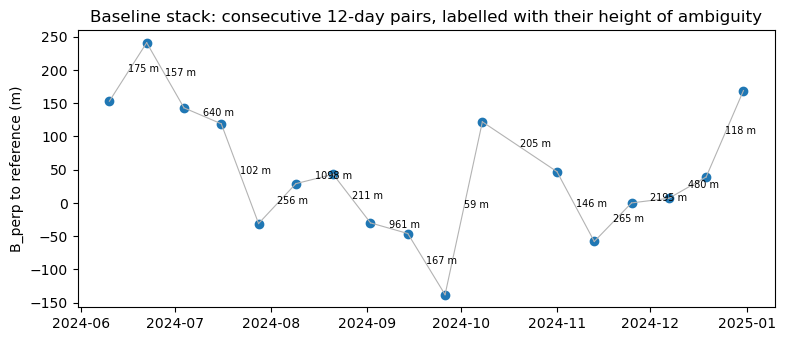

In [5]:
import numpy as np
import matplotlib.pyplot as plt
lam, R0, theta = 0.0555, 880e3, np.radians(39)
st["date"] = pd.to_datetime(st.date)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(st.date, st.bperp_m)
for i in range(len(st) - 1):
    a, b = st.iloc[i], st.iloc[i + 1]
    bp = b.bperp_m - a.bperp_m
    ax.plot([a.date, b.date], [a.bperp_m, b.bperp_m], color="0.7", lw=0.8)
    if abs(bp) > 1:
        ax.text(a.date + (b.date - a.date) / 2, (a.bperp_m + b.bperp_m) / 2, f"{lam * R0 * np.sin(theta) / (2 * abs(bp)):.0f} m", fontsize=7)
ax.set_ylabel("B_perp to reference (m)"); ax.set_title("Baseline stack: consecutive 12-day pairs, labelled with their height of ambiguity")
plt.show()

## 4 · Same questions for NISAR (L band, 2025 on)

NISAR products come already processed to several levels: **RSLC** (single-look complex, radar geometry), **GSLC**
(geocoded SLC), **GCOV** (geocoded covariance: backscatter), **RUNW/GUNW** (unwrapped interferograms, radar or map
geometry), **GOFF** (pixel offsets, for fast motion). For many questions the interferogram is ready: no need to
process SLCs yourself.

In [6]:
nis = asf.search(dataset="NISAR", intersectsWith=point, processingLevel=["GUNW", "GCOV", "GOFF"], start="2026-09-01", end="2026-11-16")
nd = pd.DataFrame([{"level": r.properties.get("processingLevel"), "name": (r.properties.get("sceneName") or r.properties.get("fileID"))[:75]} for r in nis])
print(nd.level.value_counts().to_string()); nd.head(10)

level
GCOV    23
GOFF    16
GUNW    14


,level,name
0,GCOV,NISAR_L2_UR_GCOV_035_055_A_020_4005_DHDH_A_202...
1,GCOV,NISAR_L2_PR_GCOV_035_055_A_020_4005_DHDH_A_202...
2,GUNW,NISAR_L2_UR_GUNW_033_156_A_020_034_4000_SH_202...
3,GOFF,NISAR_L2_UR_GOFF_033_156_A_020_034_4000_SH_202...
4,GCOV,NISAR_L2_UR_GCOV_034_156_A_020_4005_DHDH_A_202...
5,GCOV,NISAR_L2_PR_GCOV_034_156_A_020_4005_DHDH_A_202...
6,GCOV,NISAR_L2_PR_GCOV_034_063_D_070_4005_DHDH_A_202...
7,GUNW,NISAR_L2_UR_GUNW_033_055_A_020_034_2000_SH_202...
8,GOFF,NISAR_L2_UR_GOFF_033_055_A_020_034_2000_SH_202...
9,GCOV,NISAR_L2_UR_GCOV_034_055_A_020_4005_DHDH_A_202...


**Reading a NISAR name**: `NISAR_L2_PR_GUNW_031_055_A_020_032_2000_SH_20260922T000631_..._20261004T000631_...`:
L2 product level, PR production (UR = urgent response), cycle 031, track 055, A ascending, frame 020, secondary cycle
032, 20 MHz bandwidth (2000), SH single HH polarisation, then reference and secondary start and stop times.

## 5 · Downloading safely

Rules that save hours:

1. **Credentials stay out of code.** Put your Earthdata login in `~/.netrc` (`_netrc` on Windows):
   `machine urs.earthdata.nasa.gov login YOU password ...`. Never paste a password into a notebook.
2. **Check size first**, and the free disk space.
3. **Download to a temporary name, rename when complete**, so a broken download never looks finished.
4. **Skip what you already have**: re-running must not re-download.
5. **Keep the raw files read-only and untouched**; all processing writes new files.

Below we only fetch a small browse image, to show the pattern.

In [7]:
import netrc, os, shutil
from pathlib import Path

def session():
    n = netrc.netrc(os.path.expanduser("~/_netrc" if os.name == "nt" else "~/.netrc"))
    user, _, pw = n.authenticators("urs.earthdata.nasa.gov")
    return asf.ASFSession().auth_with_creds(user, pw)

def fetch(url, folder, s):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    out = folder / url.split("/")[-1]
    if out.exists():
        return out, "already here"
    part = out.with_suffix(out.suffix + ".part")
    with s.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(part, "wb") as f:
            shutil.copyfileobj(r.raw, f)
    part.rename(out)
    return out, "downloaded"

s = session()
browse = res[0].properties.get("browse") or []
print("free disk (GB):", round(shutil.disk_usage(".").free / 1e9))
if browse:
    print(fetch(browse[0], "downloads", s))

free disk (GB): 497


For the real thing (several GB each), the same pattern: `product.download(path=..., session=s)` in `asf_search`, or
ask ASF to process the pair on its servers (HyP3, notebook 03) and download only the result (~1 GB).

Next: **02 · Reading and cleaning backscatter**.